Visualization of stack overflow traffic over time, using data obtained from https://data.stackexchange.com/stackoverflow/query/1882532/questions-per-month?ref=blog.pragmaticengineer.com

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

from bettercode.utils import save_fig_variants

IMAGE_DIR = Path('../../latex/figures')
CHAPTER = 5

In [2]:
data = pd.read_csv('../../data/stackoverflow/QueryResults.csv')
data.columns=['Date', 'Count']
data.head()

,Date,Count
0,2008-07-01 00:00:00,6
1,2008-08-01 00:00:00,5346
2,2008-09-01 00:00:00,17688
3,2008-10-01 00:00:00,17716
4,2008-11-01 00:00:00,15072


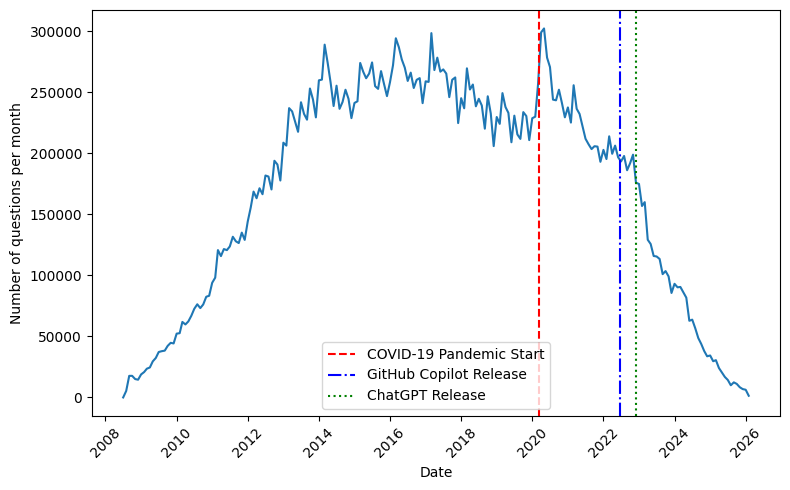

In [3]:
# Convert Date to datetime for proper plotting
data['Date'] = pd.to_datetime(data['Date'])

# Each event line gets its own line style so the three are distinguishable
# even in grayscale; the color variant keeps distinct colors as well.
events = [
    ('2020-03-11', 'COVID-19 Pandemic Start', '--', 'red'),
    ('2022-06-21', 'GitHub Copilot Release', '-.', 'blue'),
    ('2022-11-30', 'ChatGPT Release', ':', 'green'),
]


def make_stackoverflow(variant):
    line_color = 'black' if variant == 'gray' else None
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.lineplot(data=data, x='Date', y='Count', ax=ax, color=line_color)
    ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('Number of questions per month')
    for date, label, style, color in events:
        ax.axvline(x=pd.to_datetime(date),
                   color='black' if variant == 'gray' else color,
                   linestyle=style, label=label)
    ax.legend()
    fig.tight_layout()
    return fig


save_fig_variants(make_stackoverflow, 'stackoverflow', CHAPTER, IMAGE_DIR)
make_stackoverflow('color')
plt.show()